# Week 3, Tuesday: Hierarchical Clustering + PCA Visualisation
Two parts:
1. **Hierarchical clustering** on the Mall data: dendrogram, linkage, and a comparison with yesterday's K-Means.
2. **Clustering on more features** (Age, Income, Spending Score, Gender) and **visualising the result with PCA**, then profiling the clusters.


## 0. Setup and load the data

In [1]:
import numpy as np, pandas as pd, os
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
sns.set_theme(style='whitegrid')
np.random.seed(42)

if os.path.exists('Mall_Customers.csv'):
    df = pd.read_csv('Mall_Customers.csv'); USING_REAL_DATA = True
else:
    USING_REAL_DATA = False
    print('!' * 70)
    print('WARNING: Mall_Customers.csv NOT FOUND. Using SYNTHETIC practice data.')
    print('Age and Gender are RANDOM here. Upload the real file before you report results.')
    print('!' * 70)
    rng = np.random.RandomState(1)
    centres = [(25, 20), (25, 80), (55, 50), (88, 17), (88, 82)]
    inc, spend = [], []
    for ci, cs in centres:
        inc += list(rng.normal(ci, 7, 40)); spend += list(rng.normal(cs, 8, 40))
    df = pd.DataFrame({'CustomerID': range(1, 201), 'Genre': rng.choice(['Male', 'Female'], 200),
                       'Age': rng.randint(18, 70, 200),
                       'Annual Income (k$)': np.clip(inc, 15, 137).round().astype(int),
                       'Spending Score (1-100)': np.clip(spend, 1, 99).round().astype(int)})
df = df.rename(columns={'Gender': 'Genre'})
print('Using real data:', USING_REAL_DATA, '| shape:', df.shape)

inc_col, spend_col = 'Annual Income (k$)', 'Spending Score (1-100)'
X2 = StandardScaler().fit_transform(df[[inc_col, spend_col]])     # the 2 features from Monday, scaled
df.head()

Using real data: True | shape: (200, 5)


,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# Part A: Hierarchical (agglomerative) clustering
**Idea:** start with every customer as their own cluster, then repeatedly **merge the two closest clusters** until only one is left. The full history of merges is a tree called a **dendrogram**. You choose the number of clusters afterwards by **cutting the tree** at a height.

**Linkage** decides what "distance between two clusters" means:
- **ward:** merge the pair that increases the within-cluster variance the least (tends to make compact, similar-sized clusters; the usual default)
- **complete:** distance between the two *farthest* points
- **average:** average distance between all pairs
- **single:** distance between the two *closest* points (can chain clusters into long strands)

## A1. The dendrogram

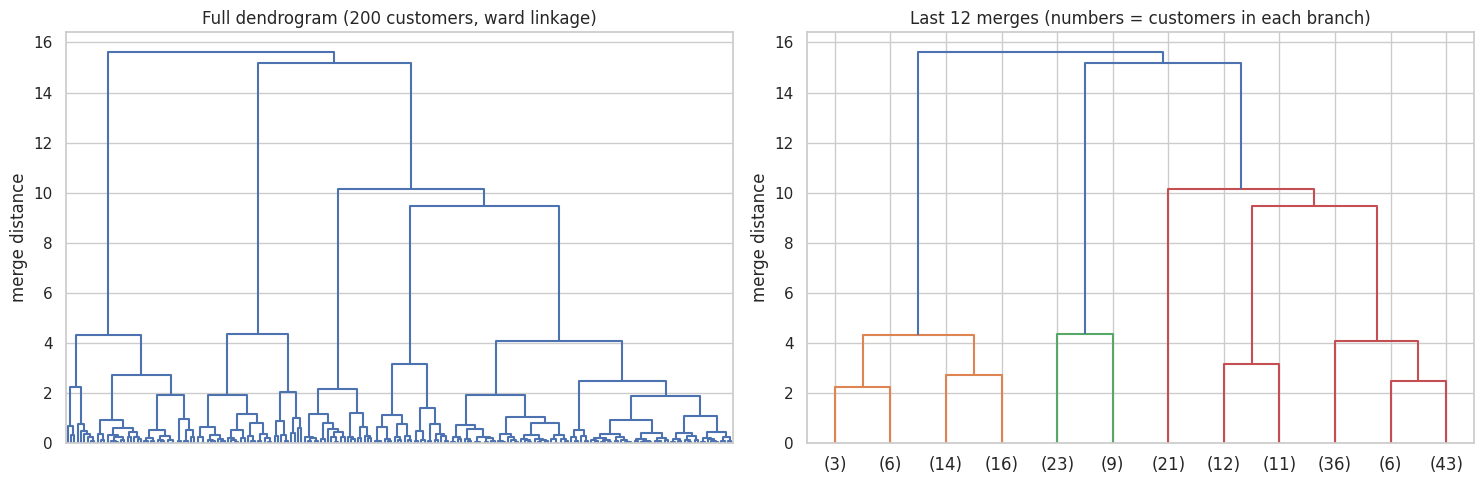

Last 8 merge distances (largest at the end): [ 3.15  4.07  4.31  4.35  9.45 10.14 15.19 15.62]


In [2]:
Z = linkage(X2, method='ward')            # Z records every merge: (cluster a, cluster b, distance, size)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
dendrogram(Z, no_labels=True, ax=ax[0], color_threshold=0)
ax[0].set(title='Full dendrogram (200 customers, ward linkage)', ylabel='merge distance')
dendrogram(Z, truncate_mode='lastp', p=12, show_leaf_counts=True, ax=ax[1])
ax[1].set(title='Last 12 merges (numbers = customers in each branch)', ylabel='merge distance')
plt.tight_layout(); plt.show()
print('Last 8 merge distances (largest at the end):', np.round(Z[-8:, 2], 2))

## A2. Cut the tree at k clusters, and draw the cut line

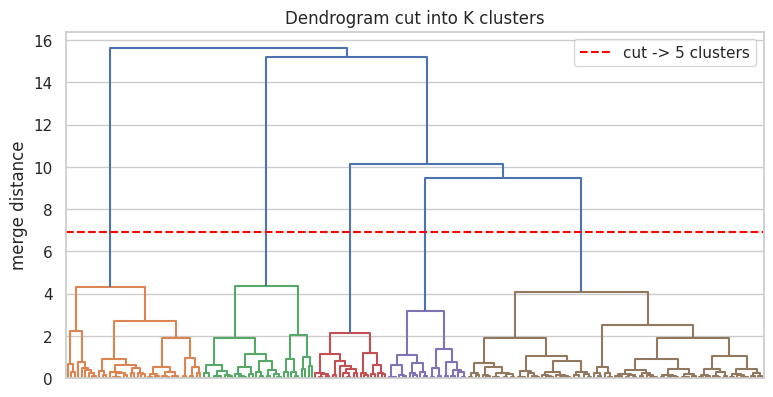

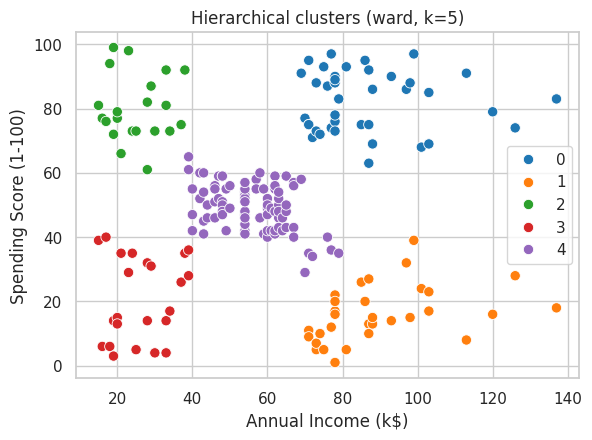

In [3]:
K = 5       # change this to the k YOU decided on
labels_h = fcluster(Z, t=K, criterion='maxclust') - 1
cut = (Z[-K, 2] + Z[-(K - 1), 2]) / 2        # a height that gives exactly K clusters
plt.figure(figsize=(9, 4.5))
dendrogram(Z, no_labels=True, color_threshold=cut)
plt.axhline(cut, color='red', ls='--', label=f'cut -> {K} clusters'); plt.legend()
plt.title('Dendrogram cut into K clusters'); plt.ylabel('merge distance'); plt.show()

plt.figure(figsize=(6.5, 4.5))
sns.scatterplot(x=df[inc_col], y=df[spend_col], hue=labels_h, palette='tab10', s=55)
plt.title(f'Hierarchical clusters (ward, k={K})'); plt.show()

## A3. Does the linkage choice matter?

In [4]:
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    lab = AgglomerativeClustering(n_clusters=K, linkage=link).fit_predict(X2)
    rows.append((link, round(silhouette_score(X2, lab), 3), sorted(np.bincount(lab), reverse=True)))
pd.DataFrame(rows, columns=['linkage', 'silhouette', 'cluster sizes'])

,linkage,silhouette,cluster sizes
0,ward,0.554,"[85, 39, 32, 23, 21]"
1,complete,0.553,"[79, 39, 38, 23, 21]"
2,average,0.479,"[102, 38, 36, 21, 3]"
3,single,0.276,"[195, 2, 1, 1, 1]"


## A4. Hierarchical vs K-Means: do they find the same groups?
The **Adjusted Rand Index (ARI)** measures how similar two clusterings are, ignoring what the clusters are *named* (cluster "0" in one can be "3" in the other). **1.0 = identical groupings, around 0 = no better than random.**

In [5]:
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X2)
agg = AgglomerativeClustering(n_clusters=K, linkage='ward').fit(X2)
print('Silhouette  K-Means     :', round(silhouette_score(X2, km.labels_), 3))
print('Silhouette  Hierarchical:', round(silhouette_score(X2, agg.labels_), 3))
print('Adjusted Rand Index (agreement):', round(adjusted_rand_score(km.labels_, agg.labels_), 3))
display(pd.crosstab(km.labels_, agg.labels_, rownames=['K-Means'], colnames=['Hierarchical']))

Silhouette  K-Means     : 0.555
Silhouette  Hierarchical: 0.554
Adjusted Rand Index (agreement): 0.942


Hierarchical,0,1,2,3,4
K-Means,,,,,
0,0,0,81,0,0
1,0,39,0,0,0
2,0,0,1,21,0
3,32,0,3,0,0
4,0,0,0,0,23


The table shows how many customers K-Means put in each cluster (rows) versus hierarchical (columns). If the two methods agree, each row has one big number and the rest are near zero.

# Part B: More features + PCA to visualise
With **2 features** we could plot the clusters directly. With **4** (Age, Income, Spending, Gender) we cannot draw a 4-D plot. **PCA** projects the data onto the **2 directions with the most variation**, so we can still look at the clusters in 2-D. (You met PCA in Week 2: it needs scaled data, and the new axes are blends of the originals.)

## B1. Build the 4-feature dataset and choose k

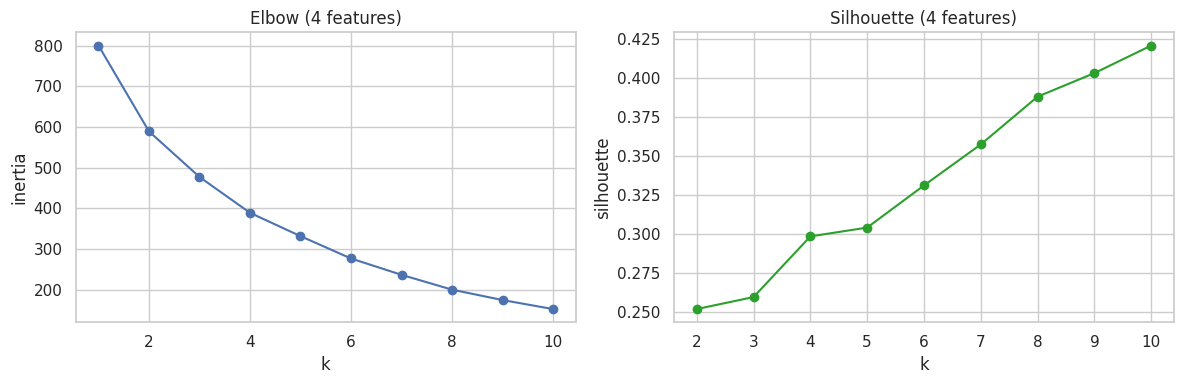

Best k by silhouette: 10  score: 0.421


In [6]:
df['Gender_num'] = (df['Genre'] == 'Male').astype(int)        # encode: Male=1, Female=0
feat4 = ['Age', inc_col, spend_col, 'Gender_num']
X4 = StandardScaler().fit_transform(df[feat4])
ks = range(2, 11)
inert = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X4).inertia_ for k in range(1, 11)]
sil = [silhouette_score(X4, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X4)) for k in ks]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 11), inert, 'o-'); ax[0].set(title='Elbow (4 features)', xlabel='k', ylabel='inertia')
ax[1].plot(list(ks), sil, 'o-', color='tab:green'); ax[1].set(title='Silhouette (4 features)', xlabel='k', ylabel='silhouette')
plt.tight_layout(); plt.show()
print('Best k by silhouette:', list(ks)[int(np.argmax(sil))], ' score:', round(max(sil), 3))

Notice that with more features the elbow is usually **less sharp** and the silhouette scores are **lower** than with just income and spending. That is normal: more dimensions mean points are less cleanly separated.

## B2. Fit K-Means on 4 features, then visualise with PCA

Variance kept by PC1, PC2: [0.337 0.262] -> total 0.599


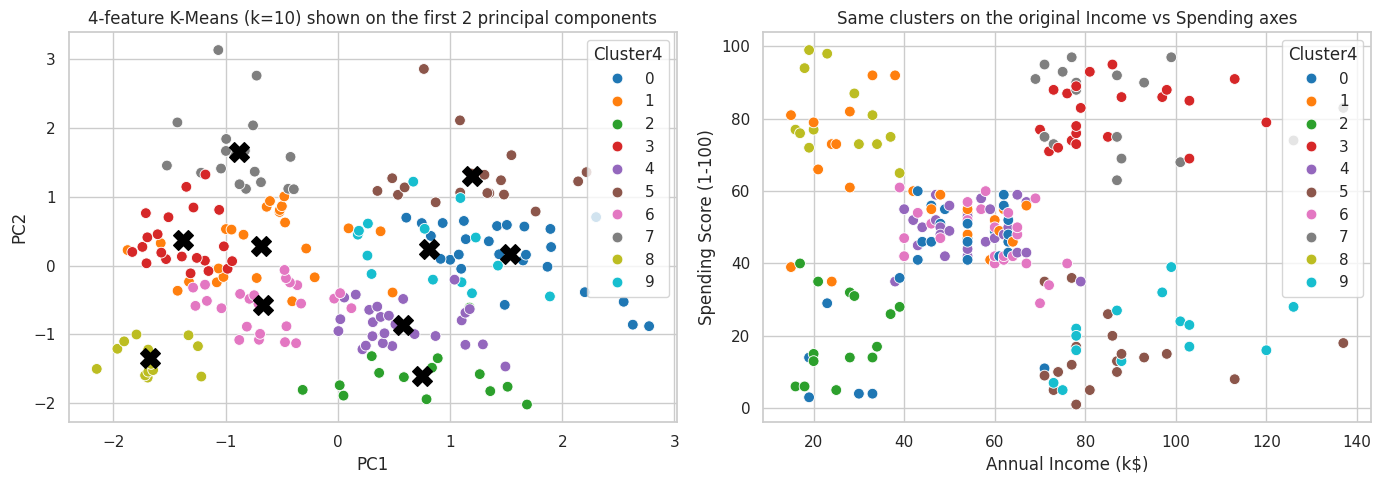

In [7]:
K4 = list(ks)[int(np.argmax(sil))]       # change this to the k YOU decide on
km4 = KMeans(n_clusters=K4, n_init=10, random_state=42).fit(X4)
df['Cluster4'] = km4.labels_

pca = PCA(n_components=2).fit(X4)
Z2 = pca.transform(X4)
print('Variance kept by PC1, PC2:', np.round(pca.explained_variance_ratio_, 3), '-> total', round(pca.explained_variance_ratio_.sum(), 3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=Z2[:, 0], y=Z2[:, 1], hue=df['Cluster4'], palette='tab10', s=60, ax=ax[0])
cent = pca.transform(km4.cluster_centers_)
ax[0].scatter(cent[:, 0], cent[:, 1], c='black', marker='X', s=200)
ax[0].set(title=f'4-feature K-Means (k={K4}) shown on the first 2 principal components', xlabel='PC1', ylabel='PC2')
sns.scatterplot(data=df, x=inc_col, y=spend_col, hue='Cluster4', palette='tab10', s=60, ax=ax[1])
ax[1].set(title='Same clusters on the original Income vs Spending axes')
plt.tight_layout(); plt.show()

In [8]:
# What do the two PCA axes MEAN? (loadings: how much each original feature contributes)
pd.DataFrame(pca.components_.T, index=['Age', 'Income', 'Spending', 'Gender'], columns=['PC1', 'PC2']).round(2)

,PC1,PC2
Age,0.69,-0.10
Income,-0.01,0.77
Spending,-0.69,0.10
Gender,0.23,0.63


**Reading the PCA plot:** each dot is a customer, coloured by cluster. If the colours form separate blobs, the clusters are well separated *in the directions that matter most*. The two plots show the **same clusters from two viewpoints**. The percentage of variance kept tells you how much of the 4-D picture the 2-D plot shows. If it is far below 100%, some separation is hidden in the dimensions we dropped. The loadings table tells you what PC1 and PC2 are made of.

## B3. Profile the clusters and name them

In [9]:
prof = df.groupby('Cluster4').agg(size=('Age', 'size'), Age=('Age', 'mean'), Income=(inc_col, 'mean'),
                                 Spending=(spend_col, 'mean'), pct_male=('Gender_num', 'mean')).round(1)
prof['pct_male'] = (prof['pct_male'] * 100).round(0)
prof

,size,Age,Income,Spending,pct_male
Cluster4,,,,,
0,26,58.8,48.7,39.8,100.0
1,24,25.2,41.2,60.9,100.0
2,14,41.2,26.1,20.1,10.0
3,21,32.2,86.0,81.7,0.0
4,26,54.2,54.2,49.0,0.0
5,19,38.5,85.9,14.2,100.0
6,25,28.0,57.4,47.1,0.0
7,18,33.3,87.1,82.7,100.0
8,13,25.5,25.7,80.5,0.0


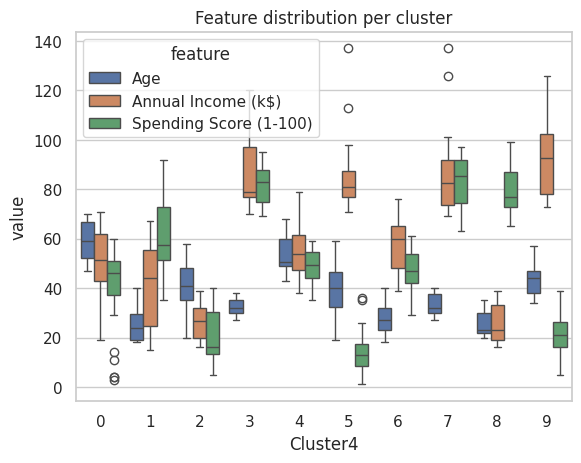

In [10]:
melt = df.melt(id_vars='Cluster4', value_vars=['Age', inc_col, spend_col], var_name='feature', value_name='value')
sns.boxplot(data=melt, x='Cluster4', y='value', hue='feature'); plt.title('Feature distribution per cluster'); plt.show()